<a href="https://colab.research.google.com/github/FatimaZahraBoukab/DeepLearning-Lab2/blob/main/Lab2_DeepLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

cuda Tesla T4


In [2]:
import torch, time
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score, accuracy_score

transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize((0.1307,), (0.3081,))])
train_ds = datasets.MNIST("./data", train=True, download=True, transform=transform)
test_ds  = datasets.MNIST("./data", train=False, download=True, transform=transform)
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_ds, batch_size=256)

100%|██████████| 9.91M/9.91M [00:00<00:00, 19.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 482kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.42MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.49MB/s]


In [4]:
def train_model(model, loader, epochs=5, lr=1e-3):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    crit = nn.CrossEntropyLoss()
    start = time.time()
    for ep in range(epochs):
        model.train(); total = 0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = crit(model(x), y)
            loss.backward(); opt.step()
            total += loss.item()
        print(f"Epoch {ep+1}: loss={total/len(loader):.4f}")
    return time.time() - start

def evaluate(model, loader):
    model.eval(); preds, labels, tot_loss = [], [], 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            tot_loss += F.cross_entropy(out, y).item()
            preds += out.argmax(1).cpu().tolist(); labels += y.cpu().tolist()
    return {"accuracy": accuracy_score(labels, preds),
            "f1": f1_score(labels, preds, average="macro"),
            "loss": tot_loss/len(loader)}

In [5]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.drop = nn.Dropout(0.25)
        self.fc1 = nn.Linear(64*7*7, 128)
        self.fc2 = nn.Linear(128, 10)
    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.drop(x.flatten(1))
        return self.fc2(F.relu(self.fc1(x)))

cnn = CNN()
t_cnn = train_model(cnn, train_loader)
res_cnn = evaluate(cnn, test_loader); res_cnn["time"] = t_cnn
print(res_cnn)

Epoch 1: loss=0.1787
Epoch 2: loss=0.0583
Epoch 3: loss=0.0420
Epoch 4: loss=0.0350
Epoch 5: loss=0.0280
{'accuracy': 0.9913, 'f1': 0.9912674997632005, 'loss': 0.024368022680573632, 'time': 82.48602342605591}


In [6]:
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_320_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

model = fasterrcnn_mobilenet_v3_large_320_fpn(weights="DEFAULT")
in_f = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_f, 11)  # 10 chiffres + fond

Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth


100%|██████████| 74.2M/74.2M [00:00<00:00, 79.6MB/s]


In [7]:
import random
from torch.utils.data import Dataset, Subset

raw_train = datasets.MNIST("./data", train=True,  transform=transforms.ToTensor())
raw_test  = datasets.MNIST("./data", train=False, transform=transforms.ToTensor())

class MNISTDetection(Dataset):
    def __init__(self, base, canvas=128):
        self.base, self.C = base, canvas
    def __len__(self): return len(self.base)
    def __getitem__(self, i):
        img, label = self.base[i]                      # 1x28x28 dans [0,1]
        rng = random.Random(i)                          # position reproductible
        s = rng.randint(40, 80)
        digit = F.interpolate(img.unsqueeze(0), size=(s, s), mode="bilinear")[0]
        x0, y0 = rng.randint(0, self.C - s), rng.randint(0, self.C - s)
        canvas = torch.zeros(1, self.C, self.C)
        canvas[:, y0:y0+s, x0:x0+s] = digit
        mask = digit[0] > 0.1
        ys = mask.any(1).nonzero().flatten(); xs = mask.any(0).nonzero().flatten()
        box = [x0 + xs.min().item(), y0 + ys.min().item(),
               x0 + xs.max().item() + 1, y0 + ys.max().item() + 1]
        target = {"boxes": torch.tensor([box], dtype=torch.float32),
                  "labels": torch.tensor([label + 1])}   # 0 = fond
        return canvas.repeat(3, 1, 1), target

collate = lambda b: tuple(zip(*b))
det_train = DataLoader(Subset(MNISTDetection(raw_train), range(8000)),
                       batch_size=32, shuffle=True, collate_fn=collate)
det_test  = DataLoader(Subset(MNISTDetection(raw_test), range(2000)),
                       batch_size=32, collate_fn=collate)

In [8]:
frcnn = model.to(device)
params = [p for p in frcnn.parameters() if p.requires_grad]
opt = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=5e-4)

start = time.time()
for ep in range(3):
    frcnn.train(); total = 0
    for imgs, tgts in det_train:
        imgs = [i.to(device) for i in imgs]
        tgts = [{k: v.to(device) for k, v in t.items()} for t in tgts]
        loss = sum(frcnn(imgs, tgts).values())
        opt.zero_grad(); loss.backward(); opt.step()
        total += loss.item()
    print(f"Epoch {ep+1}: loss={total/len(det_train):.4f}")
t_frcnn = time.time() - start

Epoch 1: loss=0.9616
Epoch 2: loss=0.4254
Epoch 3: loss=0.3450


In [10]:
preds, labels, tot_loss = [], [], 0

# Loss : en mode eval, Faster R-CNN ne renvoie pas de loss, donc on la calcule en mode train sans gradient
frcnn.train()
with torch.no_grad():
    for imgs, tgts in det_test:
        imgs = [i.to(device) for i in imgs]
        tgts = [{k: v.to(device) for k, v in t.items()} for t in tgts]
        tot_loss += sum(frcnn(imgs, tgts).values()).item()

# Prédictions : on garde la détection la plus confiante par image
frcnn.eval()
with torch.no_grad():
    for imgs, tgts in det_test:
        outs = frcnn([i.to(device) for i in imgs])
        for o, t in zip(outs, tgts):
            p = o["labels"][o["scores"].argmax()].item() - 1 if len(o["scores"]) else -1
            preds.append(p); labels.append(t["labels"].item() - 1)

results = {}
results["CNN"] = res_cnn
results["Faster R-CNN"] = {"accuracy": accuracy_score(labels, preds),
                           "f1": f1_score(labels, preds, average="macro"),
                           "loss": tot_loss / len(det_test),
                           "time": t_frcnn}
print(results["Faster R-CNN"])

{'accuracy': 0.9865, 'f1': 0.9865725441423292, 'loss': 0.3638135734058562, 'time': 212.16351127624512}


In [11]:
from torchvision import models
from torch.utils.data import Subset

tf_pre = transforms.Compose([
    transforms.Resize(224),
    transforms.Grayscale(3),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

ft_train_ds = datasets.MNIST("./data", train=True,  transform=tf_pre)
ft_test_ds  = datasets.MNIST("./data", train=False, transform=tf_pre)

ft_train = DataLoader(Subset(ft_train_ds, range(10000)), batch_size=64, shuffle=True)
ft_test  = DataLoader(Subset(ft_test_ds,  range(2000)),  batch_size=128)

In [12]:
def train_ft(model, loader, epochs=3, lr=1e-3):
    model.to(device)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    crit = nn.CrossEntropyLoss()
    start = time.time()
    for ep in range(epochs):
        model.train(); total = 0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = crit(model(x), y)
            loss.backward(); opt.step()
            total += loss.item()
        print(f"Epoch {ep+1}: loss={total/len(loader):.4f}")
    return time.time() - start

In [13]:
alex = models.alexnet(weights="DEFAULT")
for p in alex.features.parameters():
    p.requires_grad = False              # on gèle les couches convolutives
alex.classifier[6] = nn.Linear(4096, 10) # nouvelle couche de sortie (10 chiffres)

t_alex = train_ft(alex, ft_train)
res_alex = evaluate(alex, ft_test); res_alex["time"] = t_alex
results["AlexNet"] = res_alex
print(res_alex)

del alex; torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:02<00:00, 119MB/s]


Epoch 1: loss=0.3390
Epoch 2: loss=0.1308
Epoch 3: loss=0.1235
{'accuracy': 0.97, 'f1': 0.9700900344277337, 'loss': 0.14026982965879142, 'time': 88.23444700241089}


In [14]:
vgg = models.vgg16(weights="DEFAULT")
for p in vgg.features.parameters():
    p.requires_grad = False
vgg.classifier[6] = nn.Linear(4096, 10)

t_vgg = train_ft(vgg, ft_train)
res_vgg = evaluate(vgg, ft_test); res_vgg["time"] = t_vgg
results["VGG16"] = res_vgg
print(res_vgg)

del vgg; torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:04<00:00, 114MB/s]


Epoch 1: loss=0.3075
Epoch 2: loss=0.1941
Epoch 3: loss=0.1993
{'accuracy': 0.97, 'f1': 0.9702640373361897, 'loss': 0.23519866238348186, 'time': 233.83435702323914}


In [15]:
import pandas as pd
df = pd.DataFrame(results).T.round(4)
df.columns = ["Accuracy", "F1-score", "Loss", "Temps (s)"]
df

,Accuracy,F1-score,Loss,Temps (s)
CNN,0.9913,0.9913,0.0244,82.4860
Faster R-CNN,0.9865,0.9866,0.3638,212.1635
AlexNet,0.9700,0.9701,0.1403,88.2344
VGG16,0.9700,0.9703,0.2352,233.8344


In [16]:
class MHSA(nn.Module):
    def __init__(self, dim, heads):
        super().__init__()
        self.h, self.d = heads, dim // heads
        self.qkv = nn.Linear(dim, dim * 3)
        self.out = nn.Linear(dim, dim)
    def forward(self, x):
        B, N, D = x.shape
        q, k, v = self.qkv(x).reshape(B, N, 3, self.h, self.d).permute(2, 0, 3, 1, 4)
        att = ((q @ k.transpose(-2, -1)) / self.d ** 0.5).softmax(-1)
        return self.out((att @ v).transpose(1, 2).reshape(B, N, D))

class Block(nn.Module):                     # bloc Transformer encoder
    def __init__(self, dim, heads, mlp):
        super().__init__()
        self.n1, self.n2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.attn = MHSA(dim, heads)
        self.mlp = nn.Sequential(nn.Linear(dim, mlp), nn.GELU(), nn.Linear(mlp, dim))
    def forward(self, x):
        x = x + self.attn(self.n1(x))
        return x + self.mlp(self.n2(x))

class ViT(nn.Module):
    def __init__(self, patch=7, dim=64, depth=4, heads=4, mlp=128, classes=10):
        super().__init__()
        n = (28 // patch) ** 2                                  # 16 patchs de 7x7
        self.embed = nn.Conv2d(1, dim, patch, patch)            # découpage en patchs + projection linéaire
        self.cls = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos = nn.Parameter(torch.randn(1, n + 1, dim) * 0.02)
        self.blocks = nn.Sequential(*[Block(dim, heads, mlp) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, classes)
    def forward(self, x):
        x = self.embed(x).flatten(2).transpose(1, 2)            # (B, 16, dim)
        x = torch.cat([self.cls.expand(x.size(0), -1, -1), x], 1) + self.pos
        return self.head(self.norm(self.blocks(x))[:, 0])       # sortie du token [CLS]

In [17]:
vit = ViT()
t_vit = train_model(vit, train_loader, epochs=10, lr=5e-4)
res_vit = evaluate(vit, test_loader); res_vit["time"] = t_vit
results["ViT"] = res_vit
print(res_vit)

Epoch 1: loss=0.7270
Epoch 2: loss=0.2512
Epoch 3: loss=0.1586
Epoch 4: loss=0.1179
Epoch 5: loss=0.0915
Epoch 6: loss=0.0794
Epoch 7: loss=0.0656
Epoch 8: loss=0.0572
Epoch 9: loss=0.0501
Epoch 10: loss=0.0436
{'accuracy': 0.9696, 'f1': 0.969405049480003, 'loss': 0.0989719808974769, 'time': 181.25563383102417}


In [18]:
count = lambda m: sum(p.numel() for p in m.parameters())
print("CNN :", count(cnn), "| ViT :", count(vit))

CNN : 421642 | ViT : 139018


,Accuracy,F1-score,Loss,Temps (s)
CNN,0.9913,0.9913,0.0244,82.4860
Faster R-CNN,0.9865,0.9866,0.3638,212.1635
AlexNet,0.9700,0.9701,0.1403,88.2344
VGG16,0.9700,0.9703,0.2352,233.8344
ViT,0.9696,0.9694,0.0990,181.2556


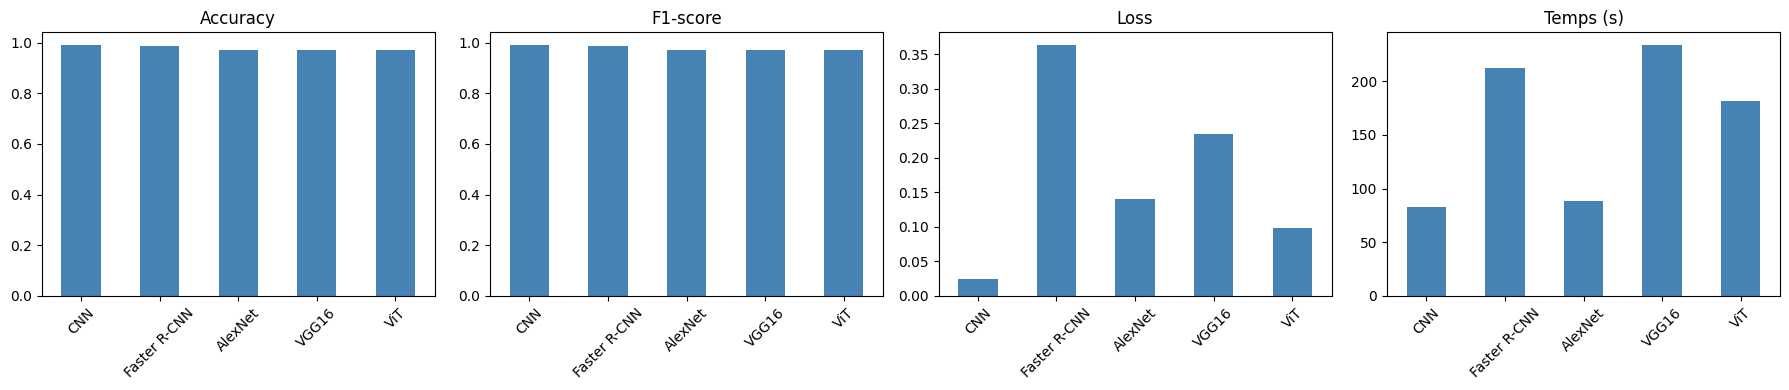

In [20]:
import matplotlib.pyplot as plt

df = pd.DataFrame(results).T.round(4)
df.columns = ["Accuracy", "F1-score", "Loss", "Temps (s)"]
display(df)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, df.columns):
    df[col].plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(col); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig("comparaison.png", dpi=150)
plt.show()